# Laboratory 2 - Web Scraping, Feature Engineering and EDA

**Course:** Introduction to Artificial Intelligence (AI-101L)   **Student:** Arham Rizwan

Real projects rarely start with a tidy table. This lab turns raw blog pages into a structured
dataset in three stages:

1. **Web scraping** - fetch article URL, title and body text (`scrape.py`).
2. **Feature engineering** - turn text into numbers with spaCy and TextBlob.
3. **Exploratory data analysis** - plot the new features and rank words with TF-IDF.

## Libraries used

| Library | Why it is here |
|---|---|
| NumPy | fast vectorised arrays (compared against a plain Python loop below) |
| requests | download the raw HTML of each page |
| BeautifulSoup + lxml | pick the title and paragraphs out of the HTML |
| pandas | hold articles and features in one table |
| spaCy | tokens, sentences, named entities, parts of speech |
| TextBlob | sentiment polarity and subjectivity |
| matplotlib / seaborn | histograms and the pair plot |
| scikit-learn | `TfidfVectorizer` for word importance |

## 0. Why NumPy: vectorised sum vs a Python loop

In [1]:
import time
import numpy as np

n = 5_000_000
values = np.random.default_rng(42).random(n)

t0 = time.perf_counter()
fast_total = values.sum()
fast_seconds = time.perf_counter() - t0

t0 = time.perf_counter()
slow_total = 0.0
for v in values:
    slow_total += v
slow_seconds = time.perf_counter() - t0

print(f"NumPy sum : {fast_total:.2f}  in {fast_seconds:.5f} s")
print(f"Loop sum  : {slow_total:.2f}  in {slow_seconds:.5f} s")
print(f"NumPy was about {slow_seconds / fast_seconds:,.0f}x faster")

NumPy sum : 2499738.14  in 0.00508 s
Loop sum  : 2499738.14  in 0.57229 s
NumPy was about 113x faster


## 1. Web scraping and data acquisition

`scrape.py` holds the scraper. It sends a browser-style `User-Agent`, reads the headline from
`h3.post-title` and the article body from `div.post-body.entry-content`, joins the paragraph
text, skips pages shorter than 100 characters, and waits one second between requests.

The cell below runs the scraper. If the site cannot be reached from the machine running this
notebook, it falls back to the copy of the data saved earlier in `articles_raw.csv`.

In [2]:
import pandas as pd
from scrape import scrape_articles

live = scrape_articles()
if len(live) > 0:
    df = live
    print("Source: live scrape,", len(df), "articles")
else:
    df = pd.read_csv("articles_raw.csv")
    print("Live scrape returned nothing - using saved articles_raw.csv:", len(df), "articles")

df.head()

[ERROR] https://techncruncher.blogspot.com/2025/01/top-10-ai-tools-that-will-transform.html -> HTTPSConnectionPool(host='techncruncher.blogspot.com', port=443): Max retries exceeded with url: /2025/01/top-10-ai-tools-that-will-transform.html (Caused by ProxyError('Unable to connect to proxy', OSError('Tunnel connection failed: 403 Forbidden')))


[ERROR] https://techncruncher.blogspot.com/2023/12/limewire-ai-studio-review-2023-details.html -> HTTPSConnectionPool(host='techncruncher.blogspot.com', port=443): Max retries exceeded with url: /2023/12/limewire-ai-studio-review-2023-details.html (Caused by ProxyError('Unable to connect to proxy', OSError('Tunnel connection failed: 403 Forbidden')))


[ERROR] https://techncruncher.blogspot.com/2023/01/top-10-ai-tools-in-2023-that-will-make.html -> HTTPSConnectionPool(host='techncruncher.blogspot.com', port=443): Max retries exceeded with url: /2023/01/top-10-ai-tools-in-2023-that-will-make.html (Caused by ProxyError('Unable to connect to proxy', OSError('Tunnel connection failed: 403 Forbidden')))


[ERROR] https://techncruncher.blogspot.com/2022/11/top-10-ai-content-generator-writer.html -> HTTPSConnectionPool(host='techncruncher.blogspot.com', port=443): Max retries exceeded with url: /2022/11/top-10-ai-content-generator-writer.html (Caused by ProxyError('Unable to connect to proxy', OSError('Tunnel connection failed: 403 Forbidden')))


[ERROR] https://techncruncher.blogspot.com/2022/09/cj-affiliate-ultimate-guide-to.html -> HTTPSConnectionPool(host='techncruncher.blogspot.com', port=443): Max retries exceeded with url: /2022/09/cj-affiliate-ultimate-guide-to.html (Caused by ProxyError('Unable to connect to proxy', OSError('Tunnel connection failed: 403 Forbidden')))
Live scrape returned nothing - using saved articles_raw.csv: 4 articles


,url,title,text
0,https://techncruncher.blogspot.com/2025/01/top...,Top 10 AI Tools That Will Transform Your Conte...,Looking to level up your content creation gam...
1,https://techncruncher.blogspot.com/2023/12/lim...,"LimeWire AI Studio Review 2023: Details, Prici...",In the rapidly advancing landscape of AI tech...
2,https://techncruncher.blogspot.com/2023/01/top...,Top 10 AI Tools in 2023 That Will Make Your Li...,"In this article, we explore the top 10 AI too..."
3,https://techncruncher.blogspot.com/2022/11/top...,Top 10 AI Content Generator & Writer Tools in ...,There are a number of different AI content ...


In [3]:
print("Shape:", df.shape)
print()
print(df["title"].to_string())
print()
print("Characters per article:", df["text"].str.len().tolist())

Shape: (4, 3)

0    Top 10 AI Tools That Will Transform Your Conte...
1    LimeWire AI Studio Review 2023: Details, Prici...
2    Top 10 AI Tools in 2023 That Will Make Your Li...
3    Top 10 AI Content Generator & Writer Tools in ...

Characters per article: [6982, 9556, 7307, 6350]


## 2. Feature engineering

### 2a. Linguistic features with spaCy
Four counts per article: tokens, sentences, named entities and nouns. Texts are processed
in one pass with `nlp.pipe`, which is faster than calling `nlp()` row by row.

In [4]:
import spacy

nlp = spacy.load("en_core_web_sm")

records = []
for doc in nlp.pipe(df["text"], batch_size=2):
    records.append({
        "num_tokens": len(doc),
        "num_sentences": sum(1 for _ in doc.sents),
        "num_entities": len(doc.ents),
        "num_nouns": sum(1 for token in doc if token.pos_ == "NOUN"),
    })

df = pd.concat([df, pd.DataFrame(records, index=df.index)], axis=1)
df["title_length"] = df["title"].str.len()

df[["title", "num_tokens", "num_sentences", "num_entities", "num_nouns", "title_length"]]

,title,num_tokens,num_sentences,num_entities,num_nouns,title_length
0,Top 10 AI Tools That Will Transform Your Conte...,1188,47,24,321,65
1,"LimeWire AI Studio Review 2023: Details, Prici...",1723,65,103,420,59
2,Top 10 AI Tools in 2023 That Will Make Your Li...,1480,52,39,331,55
3,Top 10 AI Content Generator & Writer Tools in ...,1319,63,89,271,50


### 2b. Sentiment features with TextBlob
**Polarity** runs from -1 (negative) to +1 (positive). **Subjectivity** runs from 0 (objective)
to 1 (subjective).

In [5]:
from textblob import TextBlob

sentiments = [TextBlob(text).sentiment for text in df["text"]]
df["sentiment_polarity"] = [s.polarity for s in sentiments]
df["sentiment_subjectivity"] = [s.subjectivity for s in sentiments]

df[["title", "sentiment_polarity", "sentiment_subjectivity"]].round(3)

,title,sentiment_polarity,sentiment_subjectivity
0,Top 10 AI Tools That Will Transform Your Conte...,0.229,0.584
1,"LimeWire AI Studio Review 2023: Details, Prici...",0.219,0.574
2,Top 10 AI Tools in 2023 That Will Make Your Li...,0.197,0.436
3,Top 10 AI Content Generator & Writer Tools in ...,0.215,0.565


## 3. Exploratory data analysis

### 3a. Distributions of title length and sentiment polarity

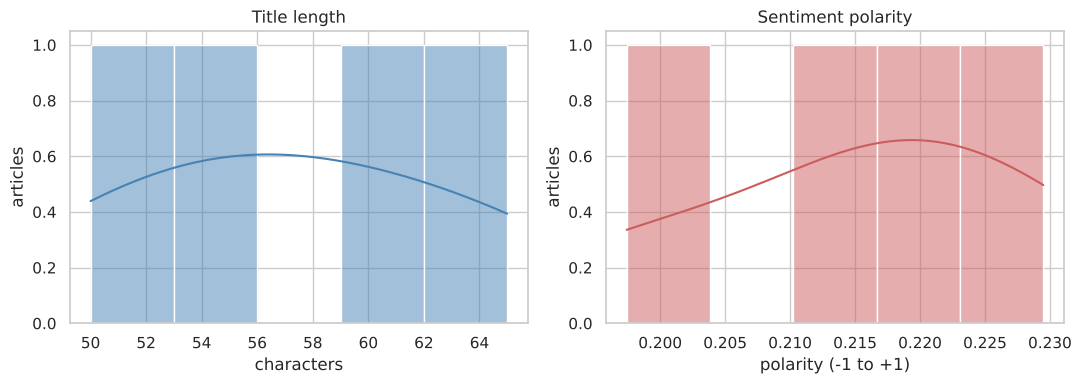

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.histplot(df["title_length"], bins=5, kde=True, color="steelblue", ax=axes[0])
axes[0].set(title="Title length", xlabel="characters", ylabel="articles")

sns.histplot(df["sentiment_polarity"], bins=5, kde=True, color="indianred", ax=axes[1])
axes[1].set(title="Sentiment polarity", xlabel="polarity (-1 to +1)", ylabel="articles")

plt.tight_layout()
plt.show()

### 3b. Pair plot of the numeric features

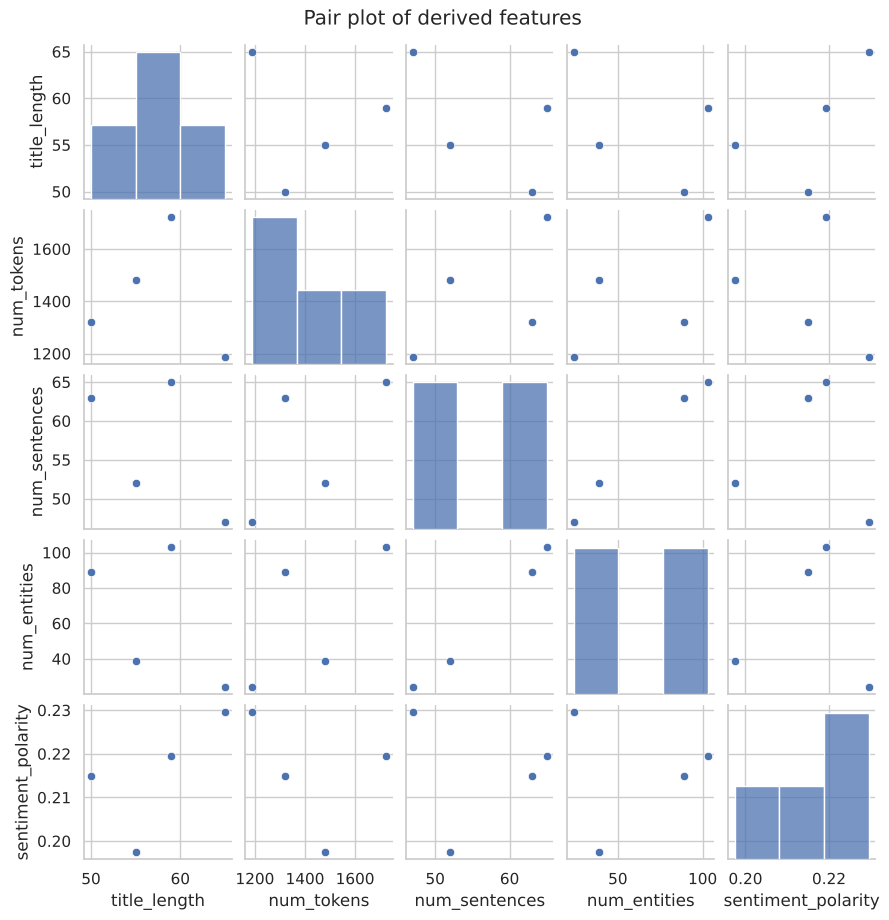

,title_length,num_tokens,num_sentences,num_entities,sentiment_polarity
title_length,1.00,-0.15,-0.58,-0.50,0.63
num_tokens,-0.15,1.00,0.64,0.65,-0.33
num_sentences,-0.58,0.64,1.00,1.00,-0.06
num_entities,-0.50,0.65,1.00,1.00,0.02
sentiment_polarity,0.63,-0.33,-0.06,0.02,1.00


In [7]:
numeric_features = ["title_length", "num_tokens", "num_sentences", "num_entities", "sentiment_polarity"]

grid = sns.pairplot(df[numeric_features], height=1.8)
grid.figure.suptitle("Pair plot of derived features", y=1.02)
plt.show()

df[numeric_features].corr().round(2)

### 3c. TF-IDF: which words matter most?
TF-IDF scores a word higher when it is frequent in one article but rare across the others.
Common English stop words are removed and only the 20 strongest terms are kept.

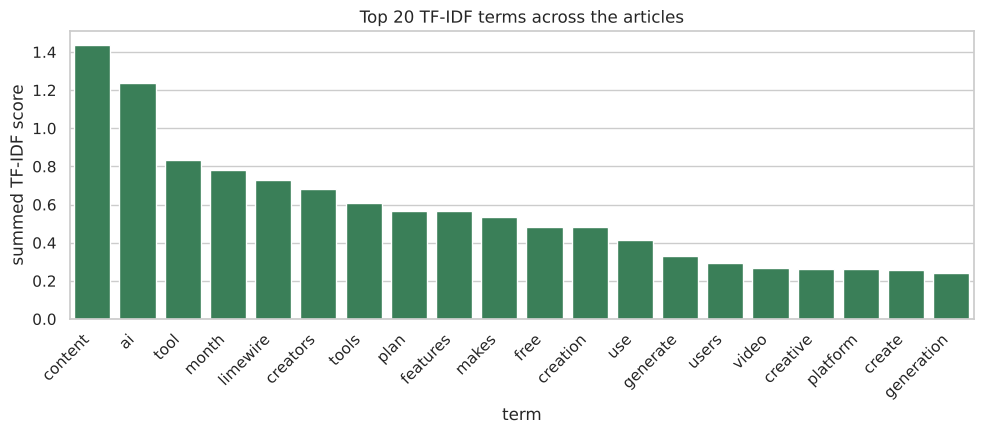

content     1.438
ai          1.238
tool        0.833
month       0.784
limewire    0.729
dtype: float64

In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(stop_words="english", max_features=20)
matrix = vectorizer.fit_transform(df["text"])
tfidf = pd.DataFrame(matrix.toarray(), columns=vectorizer.get_feature_names_out())
term_scores = tfidf.sum().sort_values(ascending=False)

plt.figure(figsize=(10, 4.5))
sns.barplot(x=term_scores.index, y=term_scores.values, color="seagreen")
plt.title("Top 20 TF-IDF terms across the articles")
plt.xlabel("term")
plt.ylabel("summed TF-IDF score")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

term_scores.head(5).round(3)

## 4. Findings (computed from the data above)

In [9]:
top_pos = df.loc[df["sentiment_polarity"].idxmax()]
longest = df.loc[df["num_tokens"].idxmax()]
most_subjective = df.loc[df["sentiment_subjectivity"].idxmax()]

print("Articles analysed          :", len(df))
print("Most positive article      :", top_pos["title"][:60], "| polarity", round(top_pos["sentiment_polarity"], 3))
print("Most subjective article    :", most_subjective["title"][:60], "| subjectivity", round(most_subjective["sentiment_subjectivity"], 3))
print("Longest article (tokens)   :", longest["title"][:60], "|", int(longest["num_tokens"]), "tokens")
print("Top 3 TF-IDF terms         :", ", ".join(term_scores.index[:3]))
print("All polarity scores > 0    :", bool((df["sentiment_polarity"] > 0).all()))

Articles analysed          : 4
Most positive article      : Top 10 AI Tools That Will Transform Your Content Creation in | polarity 0.229
Most subjective article    : Top 10 AI Tools That Will Transform Your Content Creation in | subjectivity 0.584
Longest article (tokens)   : LimeWire AI Studio Review 2023: Details, Pricing & Features | 1723 tokens
Top 3 TF-IDF terms         : content, ai, tool
All polarity scores > 0    : True


**Reading the results.** These are promotional listicle articles, so a positive polarity and a
fairly high subjectivity are what one would expect. With only a handful of articles the
correlations in the pair plot and the histogram shapes are indicative at best - a larger
scrape would be needed before drawing conclusions.